# RePaint: Inpainting with Denoising Diffusion Probabilistic Models — faithful re-implementation and evaluation
*Lugmayr et al., CVPR 2022 · [arXiv:2201.09865](https://arxiv.org/abs/2201.09865)*

This notebook takes the **`Repaint_Implementation.zip` dataset** as input, picks **5 face images**, and runs the complete RePaint pipeline as the paper specifies:

| Paper setting | This notebook |
|---|---|
| Unconditional DDPM prior; no fine-tuning | `google/ddpm-celebahq-256` (CelebA-HQ, 256×256), weights frozen |
| **T = 250** sampling steps (respaced from 1000 training steps) | Exact `space_timesteps` respacing from the authors' `guided_diffusion` code |
| **Resampling r = 10, jump length j = 10** | Exact `get_schedule_jump` schedule from the official repo |
| Algorithm 1 / Eq. 8a–8c: known region from forward process, unknown region from reverse step, mask composite | Implemented line by line (fp32 sampler arithmetic, fp16 UNet) |
| 6 mask types: Wide, Narrow, Super-Resolve 2×, Altern. Lines, Half, Expand | All 6 (Wide/Narrow use the LaMa irregular-mask generator) |
| Metric: **LPIPS (AlexNet)** | LPIPS-Alex (+ PSNR / SSIM / hole-only PSNR as extra diagnostics) |
| Ablation Table 2: slowing down vs. resampling | Re-run on CelebA (Wide masks) |
| Ablation Table 3: j ∈ {1, 5, 10} × r ∈ {5, 10, 15} | Re-run on CelebA (Wide masks) |

**Kaggle settings:** *Accelerator → GPU T4 ×2* (also runs on P100 or a single T4), *Internet → On* (model weights and LPIPS backbone download).
Add your W&B key in the configuration cell below. Everything else runs with **Run All**.

**Known deviations from the paper (stated upfront):**
1. The paper's CelebA-HQ prior is the authors' own guided-diffusion model (learned variance). Here the public Ho et al. DDPM (`google/ddpm-celebahq-256`, fixed posterior variance) is used — same family, same dataset, same resolution.
2. The test images in the zip are **CelebA** (178×218), not CelebA-HQ. They are center-cropped to 178×178 and resized to 256×256, so there is a small domain gap, and absolute LPIPS numbers are not directly comparable to Table 1. The paper used 100 test images; this notebook uses 5.
3. FID and the human user study are not computed: the paper itself notes FID needs >1,000 images, and the user study needs human raters.

## 0 · Configuration — **edit this cell**

In [ ]:
# ============================== W&B =========================================
WANDB_API_KEY  = ""                          
WANDB_PROJECT  = "repaint-cvpr22-reproduction-2"  # <-- change project name
WANDB_ENTITY   = None                        # <-- your W&B username / team (None = default entity)
WANDB_RUN_NAME = "celeba5-T250-j10-r10-2nd try"      # <-- change run name
WANDB_TAGS     = ["repaint", "ddpm", "inpainting", "celeba"]

# ============================== Data ========================================
N_IMAGES        = 5          # number of images to inpaint
IMAGE_SELECTION = "random"   # "random" (seeded) or a list of filenames, e.g. ["celeba_000.png", ...]
IMAGE_SIZE      = 256
SEED            = 2022

# ============================== Model / RePaint (paper defaults) ============
MODEL_ID        = "google/ddpm-celebahq-256"
T_STEPS         = 250        # paper: T = 250
JUMP_LENGTH     = 10         # paper: j = 10
JUMP_N_SAMPLE   = 10         # paper: r = 10
MASK_TYPES      = ["wide", "narrow", "sr2x", "altlines", "half", "expand"]
N_DIVERSITY     = 3          # extra samples (different seeds) of image #1 on Half / Expand masks

# ============================== Experiments =================================
RUN_BASELINE_NO_RESAMPLING = True   # r = 1 on all masks (shows what resampling buys)
RUN_ABLATION_JR            = True   # paper Table 3: j x r grid on Wide masks
RUN_ABLATION_SLOWDOWN      = True   # paper Table 2: slowing down vs resampling on Wide masks
ABLATION_J = [1, 5, 10]
ABLATION_R = [5, 10, 15]
SLOWDOWN_T = [250, 500, 750, 1000]  # r = 1
RESAMPLE_R = [1, 2, 3, 4]           # T = 250, j = 10

# ============================== Performance =================================
USE_FP16          = True     # fp16 UNet on Tensor Cores; sampler arithmetic stays fp32
MAX_BATCH_PER_GPU = 18       # images per UNet forward on one GPU (T4 16 GB is comfortable at 18)
CHANNELS_LAST     = True
DRY_RUN           = False    # True = tiny step counts to smoke-test the whole notebook in a few minutes

## 1 · Install, locate the zip dataset, set up the hardware

In [2]:
import subprocess, sys, importlib
def _pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)
missing = [p for p, mod in [("lpips", "lpips"), ("wandb", "wandb"), ("diffusers", "diffusers"),
                            ("opencv-python-headless", "cv2"), ("scikit-image", "skimage")]
           if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing); _pip(*missing)
print("Dependencies ready.")

Installing: ['lpips']
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 1.5 MB/s eta 0:00:00
Dependencies ready.


In [3]:
import os, shutil, zipfile
from pathlib import Path

INPUT_ROOT   = Path(os.environ.get("REPAINT_INPUT_ROOT", "/kaggle/input"))
WORKING_ROOT = Path(os.environ.get("REPAINT_WORKING_ROOT", "/kaggle/working"))
WORKING_ROOT.mkdir(parents=True, exist_ok=True)
EXTRACT_DIR = WORKING_ROOT / "repaint_project"

def _find_project(root: Path):
    """A project root is a folder that contains data/celeba with images."""
    for p in sorted(root.rglob("celeba")):
        if p.is_dir() and p.parent.name == "data" and (any(p.glob("*.png")) or any(p.glob("*.jpg"))):
            return p.parent.parent
    return None

# 1) Kaggle usually auto-extracts uploaded zips; 2) otherwise unzip any archive we find.
project = _find_project(INPUT_ROOT) if INPUT_ROOT.exists() else None
if project is None:
    for z in sorted(INPUT_ROOT.rglob("*.zip")):
        print(f"Unzipping {z} -> {EXTRACT_DIR}")
        with zipfile.ZipFile(z) as zf:
            zf.extractall(EXTRACT_DIR)
    project = _find_project(EXTRACT_DIR)
assert project is not None, f"Could not find data/celeba images under {INPUT_ROOT}. Is the zip attached as a dataset?"

# /kaggle/input is read-only, so work on a copy (code + data only; skip .git and old results)
PROJECT_ROOT = EXTRACT_DIR / project.name if not str(project).startswith(str(EXTRACT_DIR)) else project
if PROJECT_ROOT != project:
    shutil.copytree(project, PROJECT_ROOT, dirs_exist_ok=True,
                    ignore=shutil.ignore_patterns(".git", "__pycache__", "results", "Docs"))
DATA_DIR = PROJECT_ROOT / "data" / "celeba"
OUT_DIR  = WORKING_ROOT / "repaint_outputs"
FIG_DIR, CACHE_DIR = OUT_DIR / "figures", OUT_DIR / "cache"
for d in (OUT_DIR, FIG_DIR, CACHE_DIR, OUT_DIR / "samples"):
    d.mkdir(parents=True, exist_ok=True)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

all_images = sorted([p for p in DATA_DIR.iterdir() if p.suffix.lower() in {".png", ".jpg", ".jpeg"}])
print(f"Project root : {PROJECT_ROOT}")
print(f"Images found : {len(all_images)} in {DATA_DIR}")
print(f"Outputs      : {OUT_DIR}")

Project root : /kaggle/working/repaint_project/Repaint_Implementation
Images found : 20 in /kaggle/working/repaint_project/Repaint_Implementation/data/celeba
Outputs      : /kaggle/working/repaint_outputs


In [4]:
import time, math, random, json, threading, queue, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from PIL import Image
from tqdm.auto import tqdm
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICES = [torch.device(f"cuda:{i}") for i in range(torch.cuda.device_count())] or [torch.device("cpu")]
MAIN_DEVICE = DEVICES[0]
IS_CUDA = MAIN_DEVICE.type == "cuda"
if IS_CUDA:
    torch.backends.cudnn.benchmark = True       # fixed input shapes -> let cuDNN pick fastest kernels
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
USE_FP16 = USE_FP16 and IS_CUDA

if DRY_RUN:   # smoke-test sizes
    T_STEPS, JUMP_LENGTH, JUMP_N_SAMPLE = 20, 5, 2
    ABLATION_J, ABLATION_R, SLOWDOWN_T, RESAMPLE_R = [1, 5], [2, 3], [20, 40], [1, 2]

print(f"PyTorch {torch.__version__} | CUDA available: {torch.cuda.is_available()}")
for d in DEVICES:
    if d.type == "cuda":
        p = torch.cuda.get_device_properties(d)
        print(f"  {d}: {p.name}, {p.total_memory/2**30:.1f} GB, SM {p.major}.{p.minor}")
print(f"Using {len(DEVICES)} device(s); fp16 UNet = {USE_FP16}")

# --- plotting style (one consistent, colorblind-checked palette) ---
C_OURS, C_BASE, C_PAPER, C_LAMA, C_GRAY = "#2a78d6", "#eb6834", "#52514e", "#1baf7a", "#a9a8a2"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linestyle": "-", "axes.axisbelow": True,
})
MASK_LABEL = {"wide": "Wide", "narrow": "Narrow", "sr2x": "Super-Resolve 2×",
              "altlines": "Altern. Lines", "half": "Half", "expand": "Expand"}

PyTorch 2.11.0+cu128 | CUDA available: True
  cuda:0: Tesla T4, 14.6 GB, SM 7.5
  cuda:1: Tesla T4, 14.6 GB, SM 7.5
Using 2 device(s); fp16 UNet = True


## 2 · Weights & Biases
The key is read from the configuration cell, then from a Kaggle Secret named `WANDB_API_KEY`. With neither, the run is logged **offline** to `/kaggle/working/wandb` (sync later with `wandb sync`), so the notebook never blocks on a login prompt.

In [5]:
import wandb
key = (WANDB_API_KEY or "").strip()
if not key:
    try:
        from kaggle_secrets import UserSecretsClient
        key = UserSecretsClient().get_secret("WANDB_API_KEY") or ""
    except Exception:
        key = ""
os.environ.setdefault("WANDB_DIR", str(WORKING_ROOT))
os.environ["WANDB_SILENT"] = "true"
if key:
    wandb.login(key=key, relogin=True)
    WANDB_MODE = "online"
else:
    WANDB_MODE = "offline"
    print("No W&B key found -> logging offline. Paste a key in the config cell for live dashboards.")

run = wandb.init(
    project=WANDB_PROJECT, entity=WANDB_ENTITY, name=WANDB_RUN_NAME, tags=WANDB_TAGS, mode=WANDB_MODE,
    config=dict(model=MODEL_ID, T=T_STEPS, jump_length=JUMP_LENGTH, resample_r=JUMP_N_SAMPLE,
                mask_types=MASK_TYPES, n_images=N_IMAGES, image_size=IMAGE_SIZE, seed=SEED,
                fp16=USE_FP16, n_gpus=len(DEVICES), dry_run=DRY_RUN,
                gpu=torch.cuda.get_device_name(0) if IS_CUDA else "cpu",
                paper="RePaint, Lugmayr et al., CVPR 2022 (arXiv:2201.09865)"),
)
print("W&B run:", run.url if WANDB_MODE == "online" else f"offline at {run.dir}")

def show_and_log(fig, key, caption=None):
    """Save to disk, log to W&B, and display inline."""
    path = FIG_DIR / f"{key.replace('/', '__')}.png"
    fig.savefig(path)
    wandb.log({key: wandb.Image(str(path), caption=caption)})
    plt.show()

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)


W&B run: https://wandb.ai/23dcs024-national-institute-of-technology-hamirpur/repaint-cvpr22-reproduction-2/runs/qflw12f5


## 3 · Data: select and preprocess 5 images
CelebA test images are 178×218 (aligned faces). They are center-cropped to a square and resized to 256×256 with Lanczos filtering, then mapped to [-1, 1], which is the DDPM input range.

Selected: ['celeba_001', 'celeba_009', 'celeba_014', 'celeba_017', 'celeba_018'] | tensor (5, 3, 256, 256) range [-1.00, 1.00]


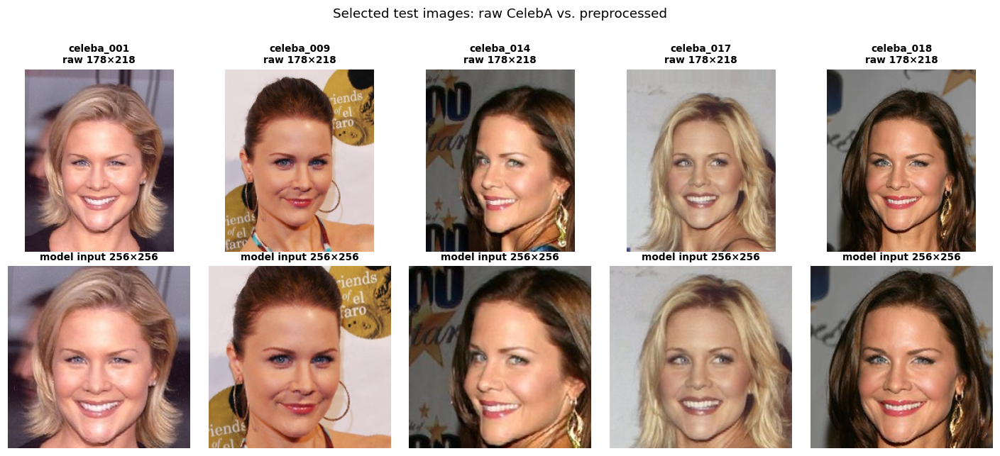

In [6]:
if isinstance(IMAGE_SELECTION, (list, tuple)):
    sel_paths = [DATA_DIR / n for n in IMAGE_SELECTION][:N_IMAGES]
else:
    sel_paths = sorted(random.Random(SEED).sample(all_images, k=min(N_IMAGES, len(all_images))))
N_IMAGES = len(sel_paths)

def preprocess(path, size=IMAGE_SIZE):
    img = Image.open(path).convert("RGB")
    w, h = img.size; s = min(w, h)
    img = img.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s))
    return img.resize((size, size), Image.LANCZOS)

def pil_to_tensor(img):            # -> [3,H,W] in [-1,1]
    return torch.from_numpy(np.asarray(img, dtype=np.float32) / 127.5 - 1.0).permute(2, 0, 1)

def to_np_img(t):                  # [3,H,W] in [-1,1] -> HxWx3 uint8
    return ((t.float().clamp(-1, 1) + 1) * 127.5).round().byte().permute(1, 2, 0).cpu().numpy()

gt_pils = [preprocess(p) for p in sel_paths]
X0 = torch.stack([pil_to_tensor(im) for im in gt_pils])     # [N,3,256,256] on CPU
IMG_IDS = [p.stem for p in sel_paths]
print("Selected:", IMG_IDS, "| tensor", tuple(X0.shape), f"range [{X0.min():.2f}, {X0.max():.2f}]")

fig, axes = plt.subplots(2, N_IMAGES, figsize=(2.6 * N_IMAGES, 5.8))
for i, p in enumerate(sel_paths):
    raw = Image.open(p).convert("RGB")
    axes[0, i].imshow(raw); axes[0, i].set_title(f"{IMG_IDS[i]}\nraw {raw.size[0]}×{raw.size[1]}", fontsize=9)
    axes[1, i].imshow(gt_pils[i]); axes[1, i].set_title(f"model input {IMAGE_SIZE}×{IMAGE_SIZE}", fontsize=9)
for a in axes.ravel(): a.axis("off")
fig.suptitle("Selected test images: raw CelebA vs. preprocessed", y=1.0)
plt.tight_layout(); show_and_log(fig, "data/selected_images")

## 4 · The six mask distributions from the paper
Convention used everywhere below: **m = 1 marks a known pixel, m = 0 marks a pixel to inpaint** (paper notation, Eq. 8c).

* **Wide / Narrow** — the paper reuses LaMa's test masks. They are generated with LaMa's irregular-stroke and box generator (thick and thin settings for 256 px), seeded per image.
* **Super-Resolve 2×** — keeps only pixels at stride 2 in height and width (25 % known).
* **Altern. Lines** — removes every second row.
* **Half** — the left half of the image is given as input.
* **Expand** — only a centered 64×64 crop is given (1/16 of the pixels).

> The `src/mask.py` in the zip returns 1 for the region to *repaint*, but `src/repaint.py` treats 1 as *known*. Combined, the old pipeline kept the center box and regenerated the border. This notebook uses its own mask code with a single, consistent convention.

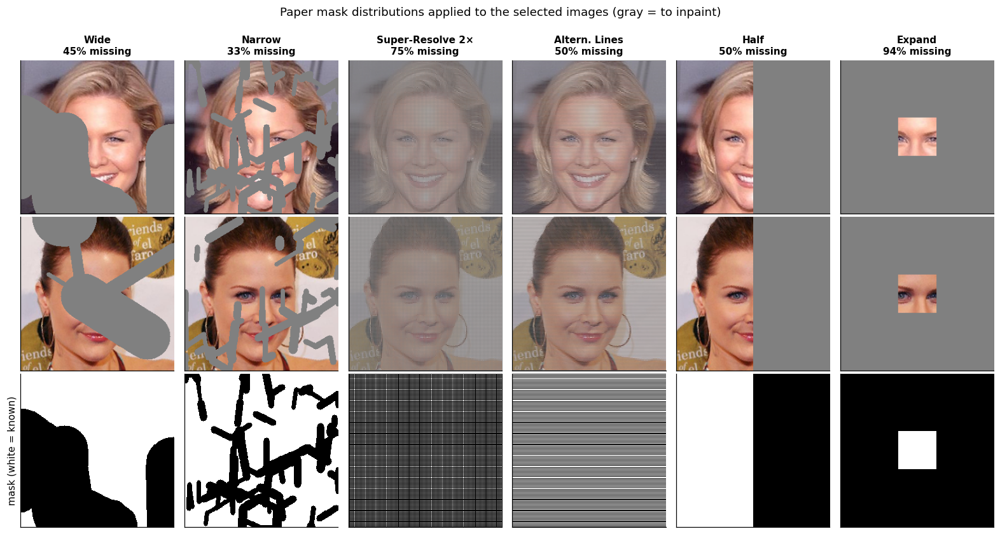

mask,Altern. Lines,Expand,Half,Narrow,Super-Resolve 2×,Wide
image,,,,,,
celeba_001,50.0,93.8,50.0,33.1,75.0,44.9
celeba_009,50.0,93.8,50.0,22.1,75.0,34.3
celeba_014,50.0,93.8,50.0,45.6,75.0,28.2
celeba_017,50.0,93.8,50.0,20.1,75.0,32.8
celeba_018,50.0,93.8,50.0,27.9,75.0,23.6


In [7]:
import cv2

def _irregular(rng, H, W, max_angle, max_len, max_width, min_times, max_times):
    """LaMa make_random_irregular_mask (1 = hole)."""
    mask = np.zeros((H, W), np.float32)
    for i in range(rng.randint(min_times, max_times + 1)):
        sx, sy = rng.randint(W), rng.randint(H)
        for _ in range(1 + rng.randint(5)):
            angle = 0.01 + rng.randint(max_angle)
            if i % 2 == 0:
                angle = 2 * 3.1415926 - angle
            length = 10 + rng.randint(max_len)
            bw = 5 + rng.randint(max_width)
            ex = int(np.clip(sx + length * np.sin(angle), 0, W))
            ey = int(np.clip(sy + length * np.cos(angle), 0, H))
            cv2.line(mask, (sx, sy), (ex, ey), 1.0, bw)
            sx, sy = ex, ey
    return mask

def _boxes(rng, H, W, margin, bmin, bmax, min_times, max_times):
    """LaMa make_random_rectangle_mask (1 = hole)."""
    mask = np.zeros((H, W), np.float32)
    bmax = min(bmax, H - margin * 2, W - margin * 2)
    for _ in range(rng.randint(min_times, max_times + 1)):
        bw, bh = rng.randint(bmin, bmax), rng.randint(bmin, bmax)
        x0 = rng.randint(margin, W - margin - bw + 1); y0 = rng.randint(margin, H - margin - bh + 1)
        mask[y0:y0 + bh, x0:x0 + bw] = 1
    return mask

def make_mask(kind, size=IMAGE_SIZE, seed=0):
    """Returns float tensor [1,H,W], 1 = known, 0 = inpaint."""
    H = W = size
    rng = np.random.RandomState(seed)
    if kind in ("wide", "narrow"):
        # LaMa configs/data_gen/random_{thick,thin}_256.yaml: MixedMaskGenerator picks ONE generator
        # (irregular p=1, box p=0.3 for thick), and masks covering > 50% (max_tamper_area) are rejected.
        for _ in range(100):
            if kind == "wide":
                if rng.rand() < 1 / 1.3:
                    hole = _irregular(rng, H, W, max_angle=4, max_len=200, max_width=100, min_times=1, max_times=5)
                else:
                    hole = _boxes(rng, H, W, margin=10, bmin=30, bmax=150, min_times=1, max_times=3)
            else:
                hole = _irregular(rng, H, W, max_angle=4, max_len=40, max_width=10, min_times=4, max_times=50)
            if 0 < hole.mean() <= 0.5:
                break
    elif kind == "sr2x":
        hole = np.ones((H, W), np.float32); hole[::2, ::2] = 0
    elif kind == "altlines":
        hole = np.zeros((H, W), np.float32); hole[1::2, :] = 1
    elif kind == "half":
        hole = np.zeros((H, W), np.float32); hole[:, W // 2:] = 1
    elif kind == "expand":
        hole = np.ones((H, W), np.float32); c = (H - 64) // 2; hole[c:c + 64, c:c + 64] = 0
    else:
        raise ValueError(kind)
    return torch.from_numpy(1.0 - hole)[None]

def mask_seed(kind, img_idx):          # same mask for the same (mask type, image) in every experiment
    return SEED * 7 + 1000 * img_idx + MASK_TYPES.index(kind) if kind in MASK_TYPES else SEED + img_idx

MASKS = {(k, i): make_mask(k, seed=mask_seed(k, i)) for k in MASK_TYPES for i in range(N_IMAGES)}

def masked_view(x0, m):                # show missing pixels as mid-gray
    return to_np_img(x0 * m + (1 - m) * 0.0)

fig, axes = plt.subplots(3, len(MASK_TYPES), figsize=(2.4 * len(MASK_TYPES), 7.6))
for c, k in enumerate(MASK_TYPES):
    for r, i in enumerate([0, 1]):
        m = MASKS[(k, i)]
        axes[r, c].imshow(masked_view(X0[i], m))
    m0 = MASKS[(k, 0)]
    axes[2, c].imshow(m0[0], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axes[0, c].set_title(f"{MASK_LABEL[k]}\n{(1 - m0).mean() * 100:.0f}% missing", fontsize=10)
axes[2, 0].set_ylabel("mask (white = known)")
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([]); a.grid(False)
fig.suptitle("Paper mask distributions applied to the selected images (gray = to inpaint)", y=1.0)
plt.tight_layout(); show_and_log(fig, "data/mask_gallery")

cov = pd.DataFrame([{"mask": MASK_LABEL[k], "image": IMG_IDS[i], "missing_%": float((1 - MASKS[(k, i)]).mean() * 100)}
                    for k in MASK_TYPES for i in range(N_IMAGES)])
display(cov.pivot(index="image", columns="mask", values="missing_%").round(1))

## 5 · Load the pretrained DDPM (frozen) and benchmark it
One model replica goes onto each GPU. The UNet runs in fp16 with `channels_last` (Tensor Cores on T4 and P100), under `torch.inference_mode()`. All diffusion arithmetic stays in fp32, so mixed precision only touches the ε-prediction.

In [8]:
from diffusers import UNet2DModel, DDPMScheduler

base_sched = DDPMScheduler.from_pretrained(MODEL_ID)
print("Scheduler:", {k: base_sched.config[k] for k in ["num_train_timesteps", "beta_schedule", "beta_start", "beta_end", "variance_type", "clip_sample"]})
BASE_ALPHAS_CUMPROD = base_sched.alphas_cumprod.double()     # [1000]
NUM_TRAIN_T = len(BASE_ALPHAS_CUMPROD)

UNETS = {}
for d in DEVICES:
    m = UNet2DModel.from_pretrained(MODEL_ID).eval().requires_grad_(False)
    if USE_FP16: m = m.half()
    if CHANNELS_LAST: m = m.to(memory_format=torch.channels_last)
    UNETS[d] = m.to(d)
n_params = sum(p.numel() for p in UNETS[MAIN_DEVICE].parameters())
print(f"UNet: {n_params/1e6:.1f} M parameters, replicated on {len(DEVICES)} device(s)")

@torch.inference_mode()
def eps_model(unet, x, t_model):
    dt = torch.float16 if USE_FP16 else torch.float32
    xin = x.to(dt)
    if CHANNELS_LAST: xin = xin.contiguous(memory_format=torch.channels_last)
    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_FP16):
        return unet(xin, t_model).sample.float()

# ---- throughput benchmark (seconds per UNet forward vs batch size) ----
bench = []
for bs in sorted({1, 4, min(8, MAX_BATCH_PER_GPU), MAX_BATCH_PER_GPU}):
    x = torch.randn(bs, 3, IMAGE_SIZE, IMAGE_SIZE, device=MAIN_DEVICE)
    t = torch.full((bs,), 500, device=MAIN_DEVICE, dtype=torch.long)
    for _ in range(2): eps_model(UNETS[MAIN_DEVICE], x, t)
    if IS_CUDA: torch.cuda.synchronize()
    n = 5 if IS_CUDA else 1
    t0 = time.time()
    for _ in range(n): eps_model(UNETS[MAIN_DEVICE], x, t)
    if IS_CUDA: torch.cuda.synchronize()
    s = (time.time() - t0) / n
    bench.append({"batch": bs, "sec_per_forward": s, "ms_per_image": 1000 * s / bs})
BENCH = pd.DataFrame(bench)
display(BENCH.round(4))
wandb.log({"perf/unet_benchmark": wandb.Table(dataframe=BENCH)})
SEC_PER_IMAGE_STEP = BENCH["sec_per_forward"].iloc[-1] / BENCH["batch"].iloc[-1]
if IS_CUDA:
    print(f"Peak memory: {torch.cuda.max_memory_allocated(MAIN_DEVICE)/2**30:.2f} GB")

scheduler_config.json:   0%|          | 0.00/256 [00:00<?, ?B/s]

Scheduler: {'num_train_timesteps': 1000, 'beta_schedule': 'linear', 'beta_start': 0.0001, 'beta_end': 0.02, 'variance_type': 'fixed_small', 'clip_sample': True}


config.json:   0%|          | 0.00/790 [00:00<?, ?B/s]

An error occurred while trying to fetch google/ddpm-celebahq-256: google/ddpm-celebahq-256 does not appear to have a file named diffusion_pytorch_model.safetensors.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


diffusion_pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  455MB            

diffusion_pytorch_model.bin: downloading bytes:           |  0.00B            

An error occurred while trying to fetch google/ddpm-celebahq-256: google/ddpm-celebahq-256 does not appear to have a file named diffusion_pytorch_model.safetensors.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


UNet: 113.7 M parameters, replicated on 2 device(s)


,batch,sec_per_forward,ms_per_image
0,1,0.1192,119.2486
1,4,0.4637,115.9185
2,8,0.9314,116.4295
3,18,2.1336,118.5324


Peak memory: 5.59 GB


## 6 · RePaint core: respacing, resampling schedule, Algorithm 1

**Respacing (T = 250).** The DDPM was trained with 1000 steps. As in the authors' `guided_diffusion.respace`, 250 evenly spaced timesteps $\tau_1<\dots<\tau_{250}$ are kept and the betas are recomputed so the chain stays exact:
$\beta'_k = 1-\bar\alpha_{\tau_k}/\bar\alpha_{\tau_{k-1}}$. The UNet is still queried at the original timestep $\tau_k$.

**One reverse step at time $t$** (Algorithm 1, lines 4–8 / Eq. 8a–8c):
$$x^{known}_{t-1}=\sqrt{\bar\alpha_{t-1}}\,x_0+\sqrt{1-\bar\alpha_{t-1}}\,\epsilon\qquad
x^{unknown}_{t-1}=\mu_\theta(x_t,t)+\sigma_t z\qquad
x_{t-1}=m\odot x^{known}_{t-1}+(1-m)\odot x^{unknown}_{t-1}$$
with $\mu_\theta$ the DDPM posterior mean, computed from the clipped $\hat x_0$ prediction (`clip_denoised=True` as in the official code). At the final step $\epsilon=z=0$, so the known region equals the input exactly.

**Resampling (Algorithm 1, line 10).** After reverse steps, the composite is diffused forward again with
$x_t=\sqrt{1-\beta_t}\,x_{t-1}+\sqrt{\beta_t}\,z$. The *jump* schedule (Appendix B, `get_schedule_jump`) goes back **j = 10** steps at a time, and each segment is sampled **r = 10** times in total. This lets the model harmonise the generated region with the known context.

> The schedule in the zip's `src/repaint.py` jumps back `jump_n_sample` *extra* times (so r = 2 there means three passes), always runs 1000 steps, and calls the forward step with misaligned betas. The implementation below follows the official code.

In [23]:
def space_timesteps(num_train, n):
    """guided_diffusion.respace.space_timesteps for a single section."""
    if n >= num_train:
        return list(range(num_train))
    frac, cur, taken = (num_train - 1) / (n - 1), 0.0, []
    for _ in range(n):
        taken.append(round(cur)); cur += frac
    return sorted(set(taken))

def get_schedule_jump(t_T, n_sample=1, jump_length=10, jump_n_sample=10):
    """Official RePaint schedule (guided_diffusion/scheduler.py). Returns list of times ending at -1."""
    jumps = {j: jump_n_sample - 1 for j in range(0, t_T - jump_length, jump_length)}
    t, ts = t_T, []
    while t >= 1:
        t -= 1; ts.append(t)
        if t + 1 < t_T - 1:
            for _ in range(n_sample - 1):
                t += 1; ts.append(t)
                if t >= 0:
                    t -= 1; ts.append(t)
        if jumps.get(t, 0) > 0:
            jumps[t] -= 1
            for _ in range(jump_length):
                t += 1; ts.append(t)
    ts.append(-1)
    return ts

def n_unet_calls(ts):
    return sum(1 for a, b in zip(ts[:-1], ts[1:]) if b < a)

_RESPACED = {}
def respaced(T, device):
    """Per-(T, device) tensors of the respaced chain (float64 for the coefficients, then fp32)."""
    key = (T, str(device))
    if key in _RESPACED: return _RESPACED[key]
    use_ts = space_timesteps(NUM_TRAIN_T, T)
    ac = BASE_ALPHAS_CUMPROD[use_ts]
    ac_prev = torch.cat([torch.ones(1, dtype=ac.dtype), ac[:-1]])
    betas = 1 - ac / ac_prev
    post_var = betas * (1 - ac_prev) / (1 - ac)                      # DDPM fixed_small variance
    d = dict(
        t_model=torch.tensor(use_ts, dtype=torch.long),
        sqrt_ac=ac.sqrt(), sqrt_1m_ac=(1 - ac).sqrt(),
        sqrt_ac_prev=ac_prev.sqrt(), sqrt_1m_ac_prev=(1 - ac_prev).sqrt(),
        coef_x0=betas * ac_prev.sqrt() / (1 - ac),                    # posterior mean coefficients
        coef_xt=(1 - ac_prev) * (1 - betas).sqrt() / (1 - ac),
        sigma=post_var.sqrt(), sqrt_beta=betas.sqrt(), sqrt_1m_beta=(1 - betas).sqrt(),
    )
    d = {k: (v.to(device) if k == "t_model" else v.float().to(device)) for k, v in d.items()}
    _RESPACED[key] = d
    return d

class PerSampleNoise:
    """One RNG stream per sample, so results do not depend on batching or on how many GPUs are used."""
    def __init__(self, seeds, shape, device):
        self.gens = [torch.Generator(device=device).manual_seed(int(s)) for s in seeds]
        self.shape, self.device = shape, device
    def __call__(self):
        return torch.stack([torch.randn(self.shape, generator=g, device=self.device) for g in self.gens])

@torch.inference_mode()
def repaint_sample(unet, x0, mask, seeds, T, jump_length, jump_n_sample, capture_local=(), n_capture=10, pbar=None):
    """RePaint Algorithm 1 with the official jump schedule.
    x0: [B,3,H,W] in [-1,1]; mask: [B,1,H,W] with 1 = known. Returns (x0_out, captures)."""
    device = x0.device
    S = respaced(T, device)
    ts = get_schedule_jump(T, 1, jump_length, jump_n_sample)
    noise = PerSampleNoise(seeds, x0.shape[1:], device)
    B = x0.shape[0]
    rev_positions = [i for i, (a, b) in enumerate(zip(ts[:-1], ts[1:])) if b < a]
    cap_at = set(np.linspace(0, len(rev_positions) - 1, n_capture).round().astype(int).tolist())
    cap_at = {rev_positions[c] for c in cap_at}
    captures = []
    x = noise()                                                       # x_T ~ N(0, I)
    for i, (t_last, t_cur) in enumerate(zip(ts[:-1], ts[1:])):
        if t_cur < t_last:                                            # ---- reverse step (Eq. 8)
            k = t_last
            eps = eps_model(unet, x, S["t_model"][k].expand(B))
            x0_hat = ((x - S["sqrt_1m_ac"][k] * eps) / S["sqrt_ac"][k]).clamp(-1, 1)
            mean = S["coef_x0"][k] * x0_hat + S["coef_xt"][k] * x
            if k > 0:
                x_unknown = mean + S["sigma"][k] * noise()                         # Eq. 8b
                x_known = S["sqrt_ac_prev"][k] * x0 + S["sqrt_1m_ac_prev"][k] * noise()  # Eq. 8a
            else:
                x_unknown, x_known = mean, x0
            x = mask * x_known + (1 - mask) * x_unknown                             # Eq. 8c
            if capture_local and i in cap_at:
                idx = list(capture_local)
                captures.append(dict(step=i, t=int(S["t_model"][k]), n_rev=rev_positions.index(i) + 1,
                                     x_t=x[idx].half().cpu(), x0_hat=x0_hat[idx].half().cpu()))
            if pbar is not None: pbar.update(1)
        else:                                                         # ---- resampling: forward one step (Eq. 1)
            k = t_cur
            x = S["sqrt_1m_beta"][k] * x + S["sqrt_beta"][k] * noise()
    return x.clamp(-1, 1), captures

# Quick self-checks on the schedule
_ts = get_schedule_jump(250, 1, 10, 10)
assert _ts[0] == 249 and _ts[-1] == -1 and all(abs(a - b) == 1 for a, b in zip(_ts[:-2], _ts[1:-1]))
print(f"Paper schedule (T=250, j=10, r=10): {len(_ts)-1} transitions, {n_unet_calls(_ts)} UNet evaluations "
      f"(vs 250 without resampling)")

Paper schedule (T=250, j=10, r=10): 4570 transitions, 2410 UNet evaluations (vs 250 without resampling)


### 6.1 · Visualising the jump schedule

Error: You must call wandb.init() before wandb.log()

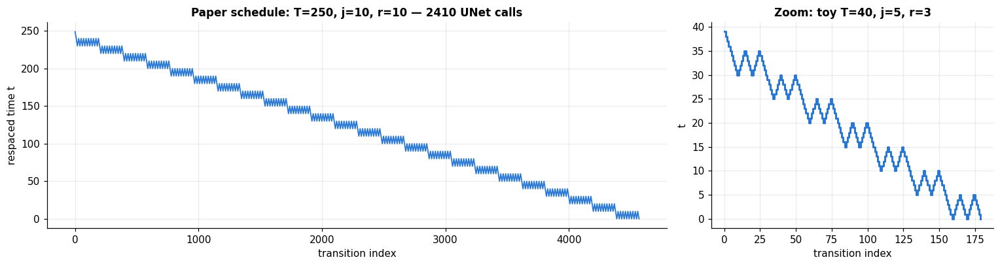

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
ts = get_schedule_jump(T_STEPS, 1, JUMP_LENGTH, JUMP_N_SAMPLE)
axes[0].plot(range(len(ts) - 1), ts[:-1], color=C_OURS, lw=1.2)
axes[0].set(xlabel="transition index", ylabel="respaced time t",
            title=f"Paper schedule: T={T_STEPS}, j={JUMP_LENGTH}, r={JUMP_N_SAMPLE} — {n_unet_calls(ts)} UNet calls")
toy = get_schedule_jump(40, 1, 5, 3)
axes[1].step(range(len(toy) - 1), toy[:-1], where="post", color=C_OURS, lw=2)
axes[1].set(xlabel="transition index", ylabel="t", title="Zoom: toy T=40, j=5, r=3")
plt.tight_layout(); show_and_log(fig, "method/jump_schedule")

## 7 · Multi-GPU job runner
Every sample is identified by `(image, mask, seed, T, j, r)`. Requests are deduplicated and cached to disk, so overlapping experiments (for example, the main run is also cell j=10/r=10 of the ablation) are computed only once. Work is packed into batches of up to `MAX_BATCH_PER_GPU` and spread over all GPUs. The longest jobs go first, and each GPU worker thread pulls the next job when it finishes.

In [11]:
CACHE_FILE = CACHE_DIR / "samples.pt"
STORE = torch.load(CACHE_FILE) if CACHE_FILE.exists() else {"samples": {}, "captures": {}}
TIMINGS = []

def item_key(img, mask, seed, T, j, r):
    return (int(img), str(mask), int(seed), int(T), int(j), int(r))

def base_seed(img, variant=0):
    return SEED + 1000 * img + 17 * variant

def run_items(items, label, capture_keys=()):
    """items: list of item_key tuples. Computes the missing ones; returns {key: [3,H,W] fp16 tensor}."""
    todo = [k for k in dict.fromkeys(items) if k not in STORE["samples"]]
    if todo:
        groups = {}
        for k in todo: groups.setdefault(k[3:], []).append(k)
        units = []
        for (T, j, r), ks in groups.items():
            calls = n_unet_calls(get_schedule_jump(T, 1, j, r))
            for s in range(0, len(ks), MAX_BATCH_PER_GPU):
                units.append((calls * len(ks[s:s + MAX_BATCH_PER_GPU]), (T, j, r), ks[s:s + MAX_BATCH_PER_GPU]))
        units.sort(key=lambda u: -u[0])                               # longest-processing-time first
        total_calls = sum(n_unet_calls(get_schedule_jump(T, 1, j, r)) for _, (T, j, r), _ in units)
        est = sum(u[0] for u in units) * SEC_PER_IMAGE_STEP / len(DEVICES)
        print(f"[{label}] {len(todo)} new samples in {len(units)} batch(es) on {len(DEVICES)} device(s); "
              f"~{est/60:.1f} min estimated")
        q = queue.Queue()
        for u in units: q.put(u)
        lock, errors, done_steps = threading.Lock(), [], [0]
        class _Counter:                       # workers only bump a counter; the main thread drives tqdm
            def update(self, n):
                with lock: done_steps[0] += n
        counter = _Counter()
        def worker(dev):
            try:
                while True:
                    try: _, (T, j, r), ks = q.get_nowait()
                    except queue.Empty: return
                    x0 = torch.stack([X0[k[0]] for k in ks]).to(dev)
                    m = torch.stack([MASKS[(k[1], k[0])] for k in ks]).to(dev)
                    cap = [i for i, k in enumerate(ks) if k in capture_keys]
                    with torch.cuda.device(dev) if dev.type == "cuda" else torch.no_grad():
                        out, caps = repaint_sample(UNETS[dev], x0, m, [k[2] for k in ks], T, j, r,
                                                   capture_local=cap, pbar=counter)
                    out = out.half().cpu()
                    with lock:
                        for i, k in enumerate(ks): STORE["samples"][k] = out[i]
                        for ci, i in enumerate(cap):
                            STORE["captures"][ks[i]] = [dict(step=c["step"], t=c["t"], n_rev=c["n_rev"],
                                                             x_t=c["x_t"][ci], x0_hat=c["x0_hat"][ci]) for c in caps]
            except Exception as e:
                errors.append(e); raise
        t0 = time.time()
        threads = [threading.Thread(target=worker, args=(d,)) for d in DEVICES]
        for th in threads: th.start()
        with tqdm(total=total_calls, desc=label, unit="step", mininterval=2) as pbar:
            while any(th.is_alive() for th in threads):
                time.sleep(1.0); pbar.n = done_steps[0]; pbar.refresh()
            pbar.n = done_steps[0]; pbar.refresh()
        for th in threads: th.join()
        if errors: raise errors[0]
        dt = time.time() - t0
        TIMINGS.append({"experiment": label, "new_samples": len(todo), "seconds": dt})
        wandb.log({f"perf/seconds_{label}": dt, f"perf/sec_per_sample_{label}": dt / len(todo)})
        torch.save(STORE, CACHE_FILE)
        print(f"[{label}] done in {dt/60:.1f} min")
    else:
        print(f"[{label}] all {len(items)} samples loaded from cache")
    return {k: STORE["samples"][k] for k in items}

## 8 · Main experiment: 5 images × 6 masks, T = 250, j = 10, r = 10
The same batch also holds `N_DIVERSITY` extra seeds for image #1 on the Half and Expand masks, which are used for the diversity figure. Trajectories (x_t and the model's x̂₀ prediction) are captured for image #1 on every mask.

In [12]:
MAIN_ITEMS = [item_key(i, k, base_seed(i), T_STEPS, JUMP_LENGTH, JUMP_N_SAMPLE) for k in MASK_TYPES for i in range(N_IMAGES)]
DIV_ITEMS = [item_key(0, k, base_seed(0, v), T_STEPS, JUMP_LENGTH, JUMP_N_SAMPLE)
             for k in ["half", "expand"] if k in MASK_TYPES for v in range(1, N_DIVERSITY + 1)]
CAPTURE = {k for k in MAIN_ITEMS if k[0] == 0}
print(f"UNet evaluations per sample: {n_unet_calls(get_schedule_jump(T_STEPS, 1, JUMP_LENGTH, JUMP_N_SAMPLE))}")
main_out = run_items(MAIN_ITEMS + DIV_ITEMS, "main_T250_j10_r10", capture_keys=CAPTURE)
for k in MAIN_ITEMS:
    Image.fromarray(to_np_img(main_out[k])).save(OUT_DIR / "samples" / f"{IMG_IDS[k[0]]}_{k[1]}_repaint.png")

UNet evaluations per sample: 2410
[main_T250_j10_r10] 36 new samples in 2 batch(es) on 2 device(s); ~85.7 min estimated


main_T250_j10_r10:   0%|          | 0/4820 [00:00<?, ?step/s]

[main_T250_j10_r10] done in 91.7 min


### 8.1 · Baseline without resampling (r = 1)
This is the naive conditioning the paper argues against (Sec. 4.2): the known region is replaced at every step, but there is no resampling. It uses the same initial noise and masks as the main run.

In [13]:
BASE_ITEMS = [item_key(i, k, base_seed(i), T_STEPS, JUMP_LENGTH, 1) for k in MASK_TYPES for i in range(N_IMAGES)]
base_out = run_items(BASE_ITEMS, "baseline_r1") if RUN_BASELINE_NO_RESAMPLING else {}

[baseline_r1] 30 new samples in 2 batch(es) on 2 device(s); ~7.4 min estimated


baseline_r1:   0%|          | 0/500 [00:00<?, ?step/s]

[baseline_r1] done in 9.7 min


## 9 · Evaluation: LPIPS (the paper's metric) + diagnostics
* **LPIPS (AlexNet)**, full image, inputs in [-1, 1] — exactly the paper's metric (lower is better).
* **PSNR / SSIM** on the full image (common in follow-up work; not reported in the paper).
* **Hole PSNR**: PSNR on the inpainted pixels only. The known pixels are copied from the input, so full-image metrics are inflated for small holes.

PSNR and SSIM reward blurry, mean-like fills. A plausible but *different* face scores low even when it looks right. The paper relies on LPIPS and a user study for this reason.

In [14]:
import lpips
from skimage.metrics import structural_similarity, peak_signal_noise_ratio
LPIPS_FN = lpips.LPIPS(net="alex", verbose=False).to(MAIN_DEVICE).eval()

@torch.inference_mode()
def evaluate(outs: dict, tag: str):
    rows = []
    keys = list(outs)
    for s in range(0, len(keys), 16):
        ks = keys[s:s + 16]
        pred = torch.stack([outs[k].float() for k in ks]).to(MAIN_DEVICE)
        gt = torch.stack([X0[k[0]] for k in ks]).to(MAIN_DEVICE)
        lp = LPIPS_FN(pred, gt).flatten().cpu().numpy()
        for i, k in enumerate(ks):
            p8, g8 = to_np_img(pred[i]), to_np_img(gt[i])
            hole = (1 - MASKS[(k[1], k[0])][0].numpy()).astype(bool)
            mse_hole = ((p8[hole].astype(np.float64) - g8[hole]) ** 2).mean() if hole.any() else np.nan
            rows.append(dict(experiment=tag, image=IMG_IDS[k[0]], img_idx=k[0], mask=k[1], seed=k[2], T=k[3], j=k[4], r=k[5],
                             LPIPS=float(lp[i]),
                             PSNR=peak_signal_noise_ratio(g8, p8, data_range=255),
                             SSIM=structural_similarity(g8, p8, channel_axis=2, data_range=255),
                             hole_PSNR=10 * np.log10(255 ** 2 / mse_hole) if mse_hole > 0 else np.inf))
    return pd.DataFrame(rows)

MAIN_TAG = f"RePaint (r={JUMP_N_SAMPLE})"
df_main = evaluate({k: main_out[k] for k in MAIN_ITEMS}, MAIN_TAG)
df_base = evaluate(base_out, "No resampling (r=1)") if base_out else pd.DataFrame()
df_all = pd.concat([df_main, df_base], ignore_index=True)

# Paper Table 1, CelebA-HQ LPIPS (100 test images)
PAPER_REPAINT = {"wide": 0.059, "narrow": 0.028, "sr2x": 0.029, "altlines": 0.009, "half": 0.165, "expand": 0.435}
PAPER_LAMA    = {"wide": 0.045, "narrow": 0.028, "sr2x": 0.177, "altlines": 0.083, "half": 0.138, "expand": 0.342}

summary = df_all.groupby(["experiment", "mask"])[["LPIPS", "PSNR", "SSIM", "hole_PSNR"]].mean().reset_index()
table1 = (summary.pivot(index="mask", columns="experiment", values="LPIPS").reindex(MASK_TYPES))
table1["Paper RePaint (CelebA-HQ)"] = [PAPER_REPAINT[k] for k in MASK_TYPES]
table1["Paper LaMa (CelebA-HQ)"] = [PAPER_LAMA[k] for k in MASK_TYPES]
table1.index = [MASK_LABEL[k] for k in MASK_TYPES]
print("LPIPS ↓ per mask type (mean over images) — compare with paper Table 1")
display(table1.round(3))
diag = summary[summary.experiment == MAIN_TAG].set_index("mask").reindex(MASK_TYPES)[["LPIPS", "PSNR", "SSIM", "hole_PSNR"]]
diag.index = [MASK_LABEL[k] for k in MASK_TYPES]
print(f"All metrics, {MAIN_TAG}")
display(diag.round(3))

wandb.log({"eval/table1_lpips": wandb.Table(dataframe=table1.reset_index().rename(columns={"index": "mask"})),
           "eval/per_image_metrics": wandb.Table(dataframe=df_all)})
for k in MASK_TYPES:
    d = df_main[df_main["mask"] == k]
    wandb.run.summary[f"lpips/{k}"] = d.LPIPS.mean()
    wandb.run.summary[f"psnr/{k}"] = d.PSNR.mean()
    wandb.run.summary[f"ssim/{k}"] = d.SSIM.mean()
wandb.run.summary["lpips/mean_all_masks"] = df_main.LPIPS.mean()
df_all.to_csv(OUT_DIR / "metrics_per_image.csv", index=False)
table1.to_csv(OUT_DIR / "table1_lpips.csv")

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 212MB/s] 


LPIPS ↓ per mask type (mean over images) — compare with paper Table 1


experiment,No resampling (r=1),RePaint (r=10),Paper RePaint (CelebA-HQ),Paper LaMa (CelebA-HQ)
Wide,0.118,0.098,0.059,0.045
Narrow,0.082,0.051,0.028,0.028
Super-Resolve 2×,0.282,0.049,0.029,0.177
Altern. Lines,0.061,0.015,0.009,0.083
Half,0.203,0.191,0.165,0.138
Expand,0.510,0.469,0.435,0.342


All metrics, RePaint (r=10)


,LPIPS,PSNR,SSIM,hole_PSNR
Wide,0.098,21.917,0.837,16.968
Narrow,0.051,27.665,0.899,22.210
Super-Resolve 2×,0.049,32.946,0.939,31.697
Altern. Lines,0.015,37.511,0.973,34.501
Half,0.191,15.376,0.673,12.365
Expand,0.469,9.122,0.300,8.842


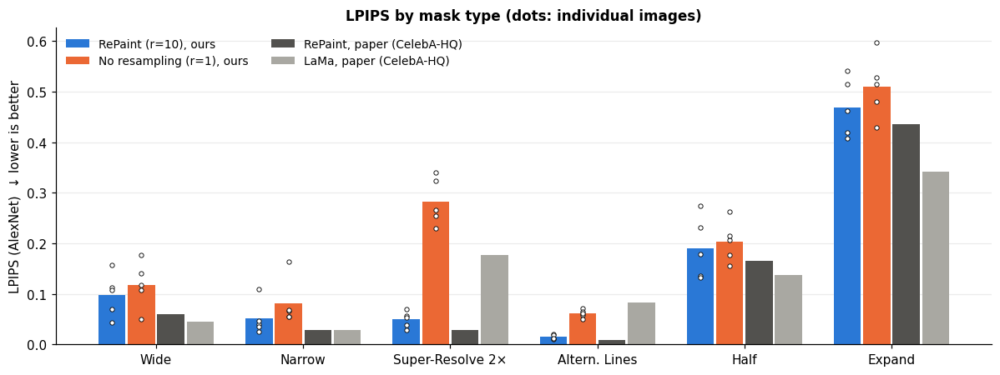

In [15]:
# LPIPS per mask: ours (dots = individual images) vs. no-resampling vs. paper
fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(len(MASK_TYPES)); w = 0.2
series = [(f"{MAIN_TAG}, ours", df_main, C_OURS)]
if len(df_base): series.append(("No resampling (r=1), ours", df_base, C_BASE))
for si, (name, d, col) in enumerate(series):
    means = [d[d["mask"] == k].LPIPS.mean() for k in MASK_TYPES]
    xs = x + (si - 1.5) * w
    ax.bar(xs, means, w * 0.92, color=col, label=name, zorder=2)
    for xi, k in zip(xs, MASK_TYPES):
        v = d[d["mask"] == k].LPIPS.values
        ax.scatter(np.full(len(v), xi), v, s=12, color="white", edgecolor="#0b0b0b", lw=0.6, zorder=3)
ax.bar(x + 0.5 * w, [PAPER_REPAINT[k] for k in MASK_TYPES], w * 0.92, color=C_PAPER, label="RePaint, paper (CelebA-HQ)", zorder=2)
ax.bar(x + 1.5 * w, [PAPER_LAMA[k] for k in MASK_TYPES], w * 0.92, color=C_GRAY, label="LaMa, paper (CelebA-HQ)", zorder=2)
ax.set_xticks(x, [MASK_LABEL[k] for k in MASK_TYPES]); ax.set_ylabel("LPIPS (AlexNet)  ↓ lower is better")
ax.set_title("LPIPS by mask type (dots: individual images)")
ax.legend(frameon=False, ncol=2, fontsize=9); ax.grid(axis="x", visible=False)
plt.tight_layout(); show_and_log(fig, "eval/lpips_by_mask")

## 10 · Qualitative results

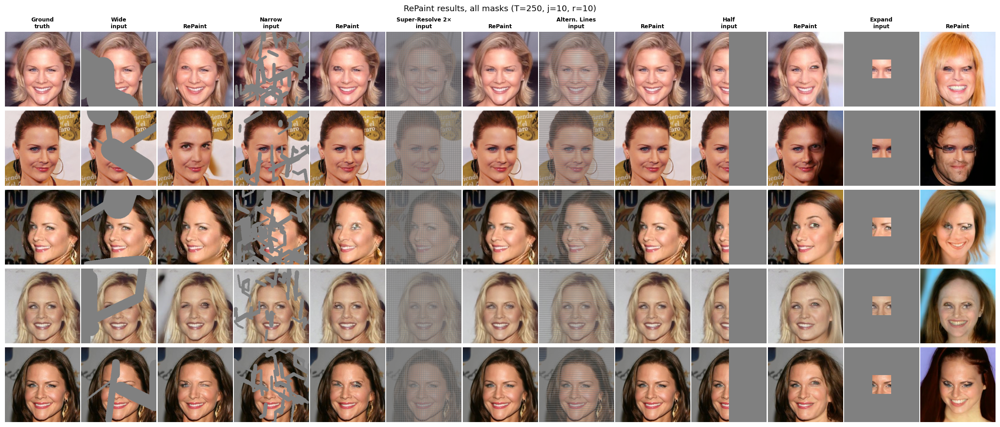

In [16]:
# Overview: every image x every mask
ncol = 2 * len(MASK_TYPES) + 1
fig, axes = plt.subplots(N_IMAGES, ncol, figsize=(1.55 * ncol, 1.6 * N_IMAGES + 0.6))
axes = np.atleast_2d(axes)
for i in range(N_IMAGES):
    axes[i, 0].imshow(to_np_img(X0[i]))
    for c, k in enumerate(MASK_TYPES):
        key = item_key(i, k, base_seed(i), T_STEPS, JUMP_LENGTH, JUMP_N_SAMPLE)
        axes[i, 1 + 2 * c].imshow(masked_view(X0[i], MASKS[(k, i)]))
        axes[i, 2 + 2 * c].imshow(to_np_img(main_out[key]))
        if i == 0:
            axes[i, 1 + 2 * c].set_title(f"{MASK_LABEL[k]}\ninput", fontsize=8)
            axes[i, 2 + 2 * c].set_title("RePaint", fontsize=8)
    if i == 0: axes[i, 0].set_title("Ground\ntruth", fontsize=8)
for a in axes.ravel(): a.axis("off")
fig.suptitle(f"RePaint results, all masks (T={T_STEPS}, j={JUMP_LENGTH}, r={JUMP_N_SAMPLE})", y=1.0)
plt.tight_layout(pad=0.2); show_and_log(fig, "results/overview_grid")

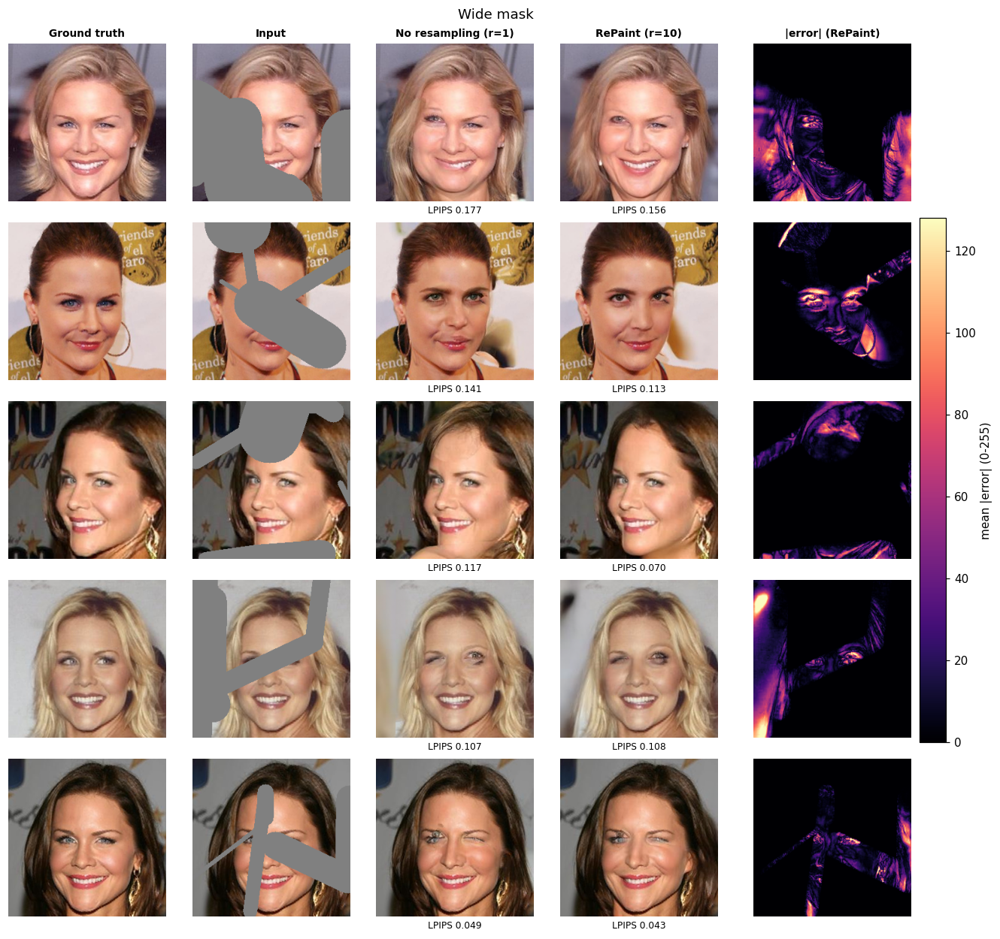

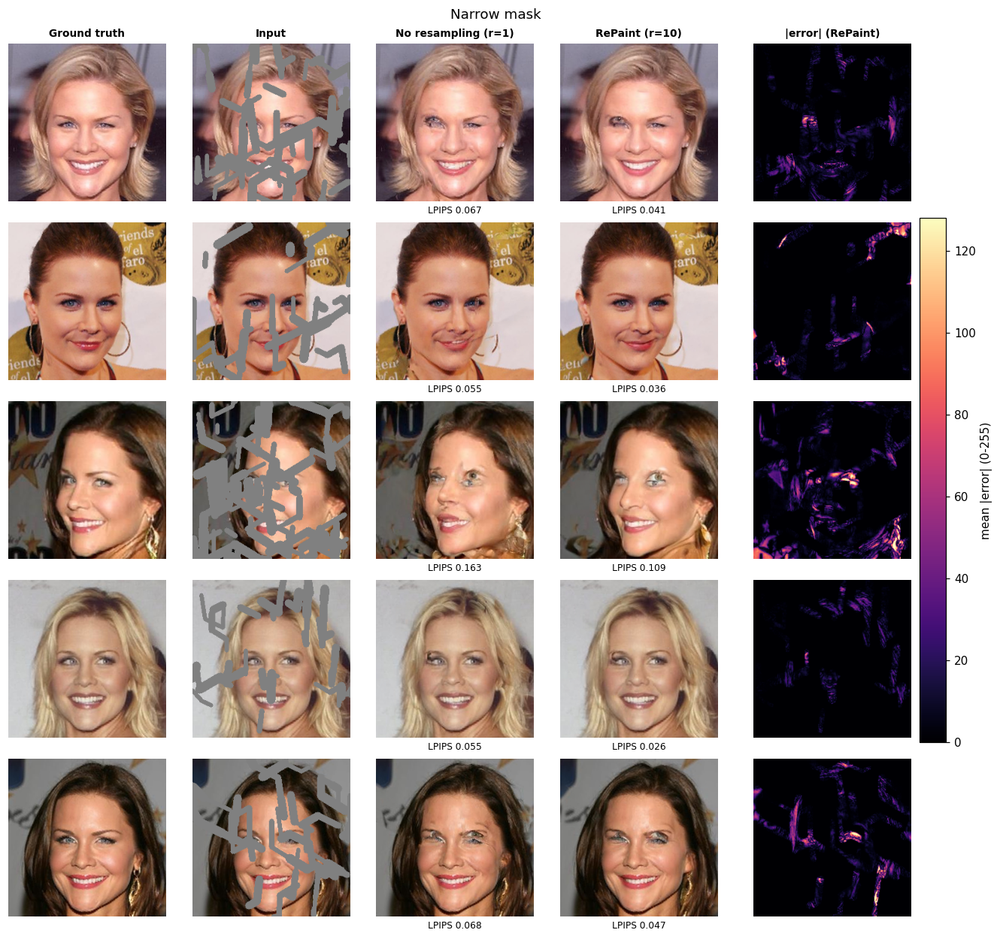

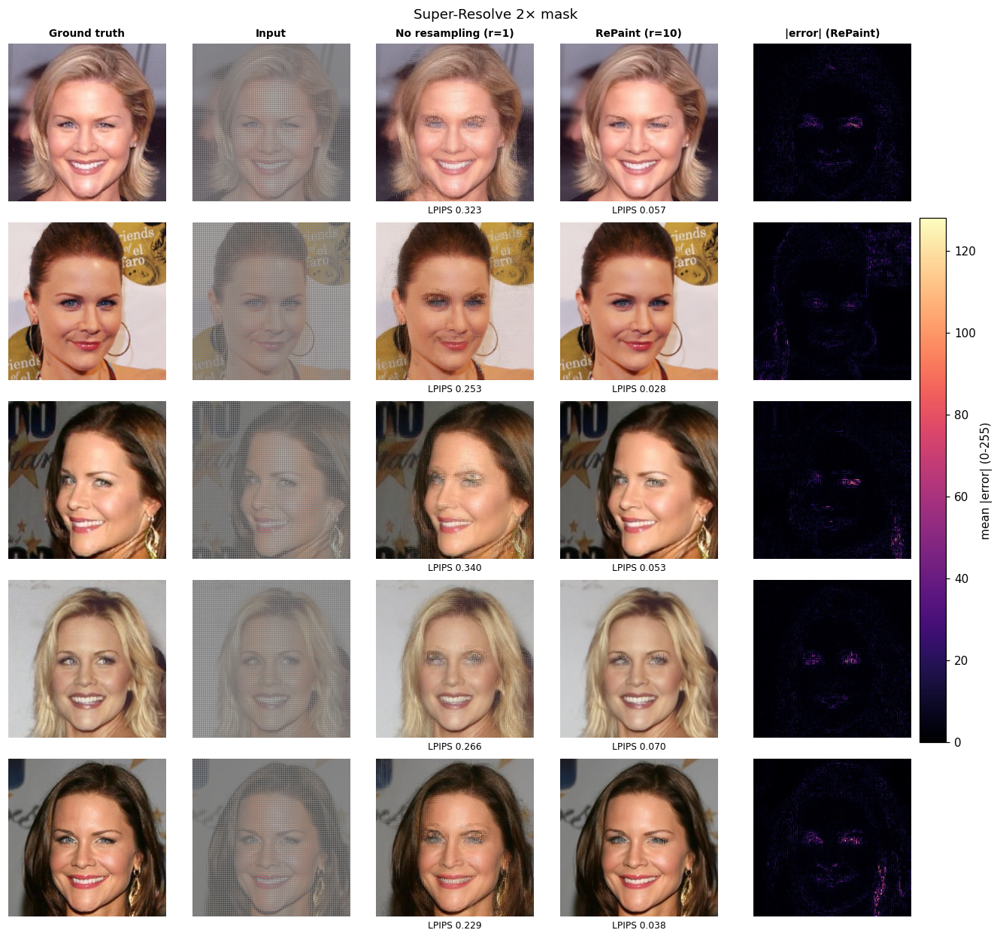

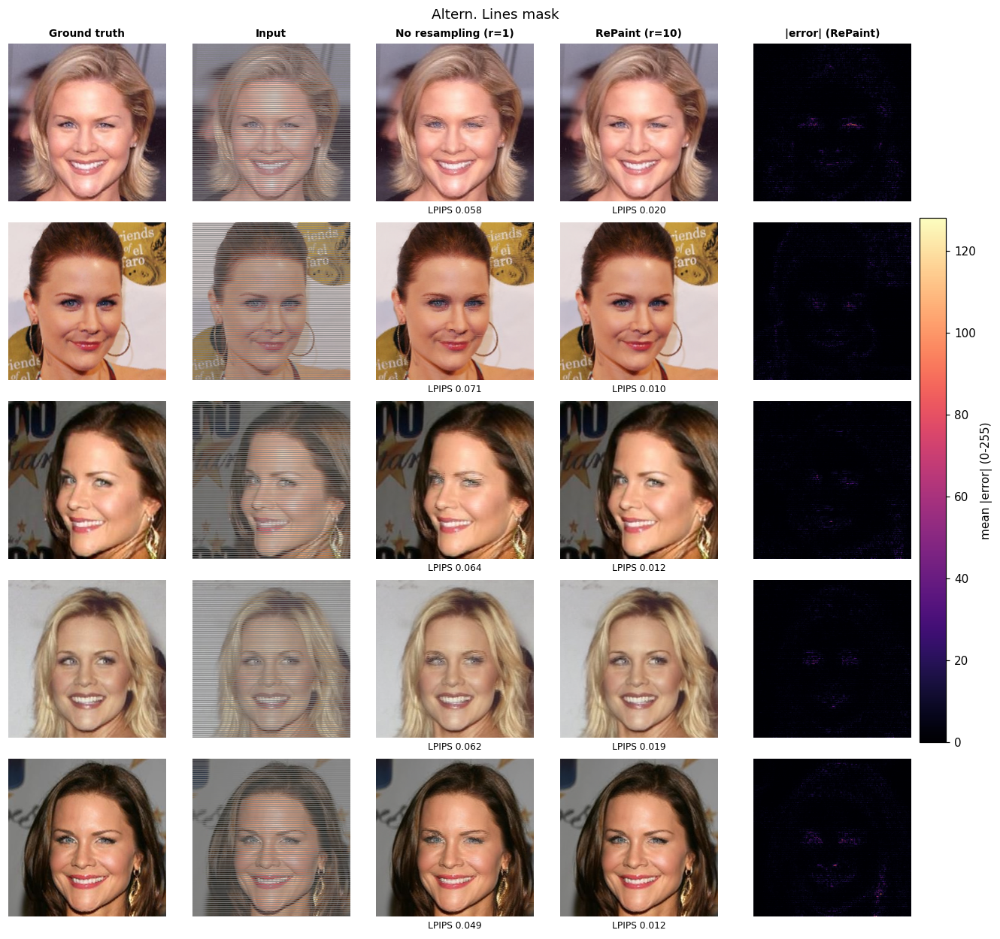

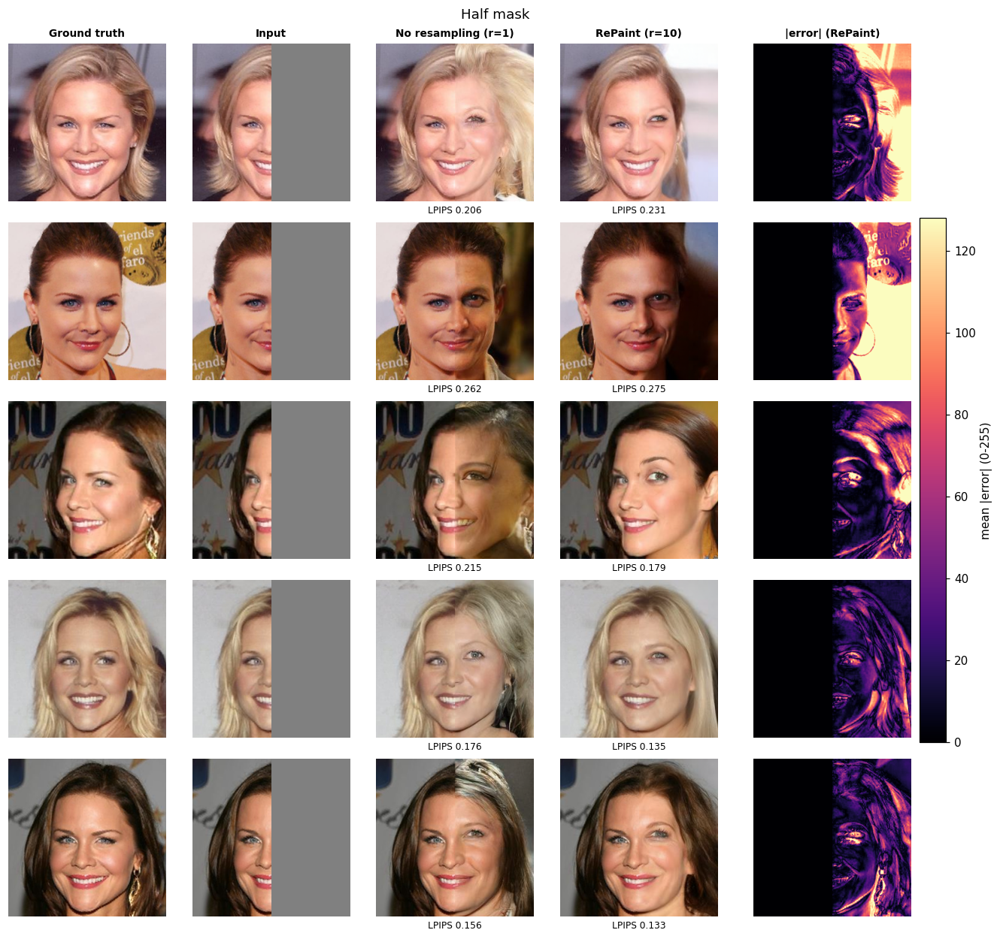

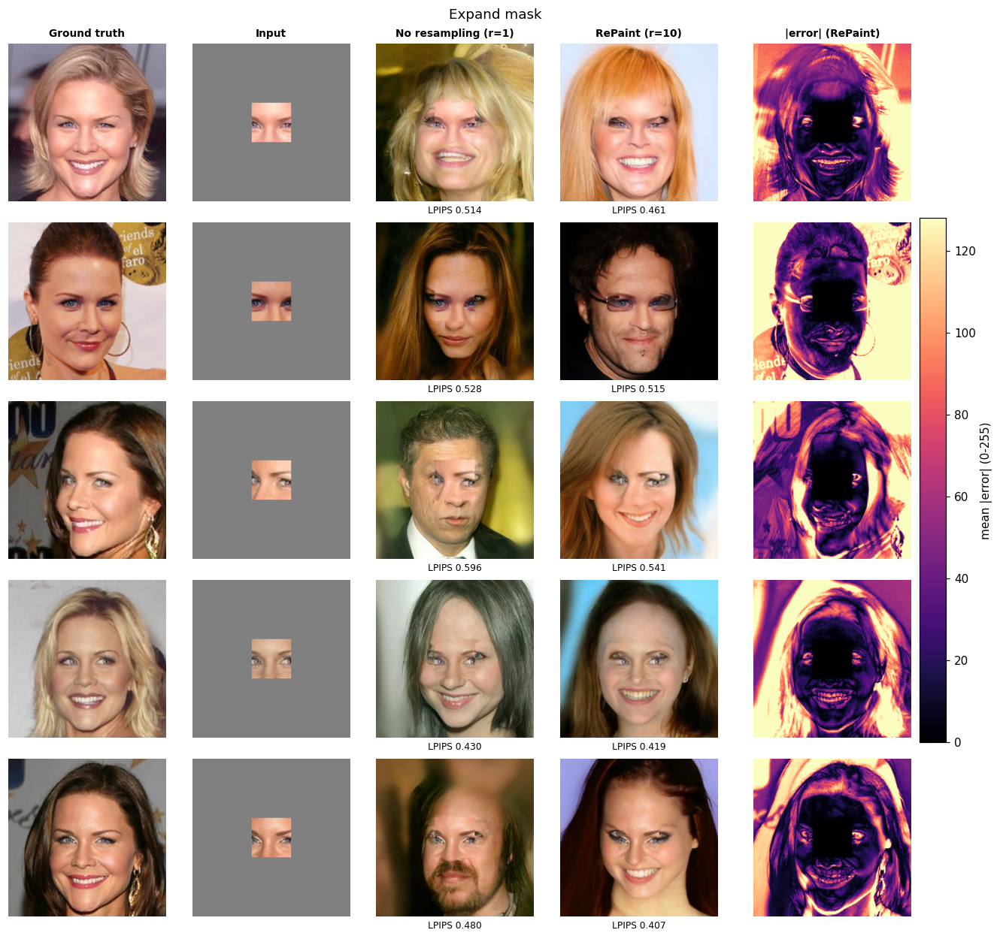

In [17]:
# Detail per mask: GT | input | no resampling | RePaint | |error| heat map
tbl = wandb.Table(columns=["image", "mask", "ground_truth", "input", "no_resampling_r1", "repaint", "abs_error",
                           "LPIPS", "LPIPS_r1", "PSNR", "SSIM", "hole_PSNR"])
for k in MASK_TYPES:
    cols = ["Ground truth", "Input", "No resampling (r=1)", f"RePaint (r={JUMP_N_SAMPLE})", "|error| (RePaint)"]
    fig, axes = plt.subplots(N_IMAGES, len(cols), figsize=(2.3 * len(cols) + 0.6, 2.25 * N_IMAGES), layout="constrained")
    axes = np.atleast_2d(axes)
    for i in range(N_IMAGES):
        key = item_key(i, k, base_seed(i), T_STEPS, JUMP_LENGTH, JUMP_N_SAMPLE)
        bkey = item_key(i, k, base_seed(i), T_STEPS, JUMP_LENGTH, 1)
        gt, inp, out = to_np_img(X0[i]), masked_view(X0[i], MASKS[(k, i)]), to_np_img(main_out[key])
        err = np.abs(out.astype(np.float32) - gt.astype(np.float32)).mean(2)
        r_main = df_main[(df_main.img_idx == i) & (df_main["mask"] == k)].iloc[0]
        r_base = df_base[(df_base.img_idx == i) & (df_base["mask"] == k)].iloc[0] if len(df_base) else None
        panels = [gt, inp, to_np_img(base_out[bkey]) if bkey in base_out else np.zeros_like(gt), out]
        for c, p in enumerate(panels): axes[i, c].imshow(p)
        im = axes[i, 4].imshow(err, cmap="magma", vmin=0, vmax=128)
        if r_base is not None: axes[i, 2].set_xlabel(f"LPIPS {r_base.LPIPS:.3f}", fontsize=8)
        axes[i, 3].set_xlabel(f"LPIPS {r_main.LPIPS:.3f}", fontsize=8)
        tbl.add_data(IMG_IDS[i], MASK_LABEL[k], wandb.Image(gt), wandb.Image(inp),
                     wandb.Image(panels[2]) if r_base is not None else None, wandb.Image(out),
                     wandb.Image((err / 128).clip(0, 1)), r_main.LPIPS, r_base.LPIPS if r_base is not None else None,
                     r_main.PSNR, r_main.SSIM, r_main.hole_PSNR)
    for c, t in enumerate(cols): axes[0, c].set_title(t, fontsize=9)
    for a in axes.ravel(): a.set_xticks([]); a.set_yticks([]); a.grid(False); [s.set_visible(False) for s in a.spines.values()]
    fig.colorbar(im, ax=axes[:, 4], shrink=0.6, label="mean |error| (0-255)")
    fig.suptitle(f"{MASK_LABEL[k]} mask")
    show_and_log(fig, f"results/detail_{k}")
wandb.log({"results/comparison_table": tbl})

### 10.1 · Inside the reverse process (cf. paper Fig. 2 / Fig. 3)
Top row: the composite $x_t$. Bottom row: the model's current estimate $\hat x_0$. The jumps let the prediction for the hole settle into a configuration that agrees with the known context.

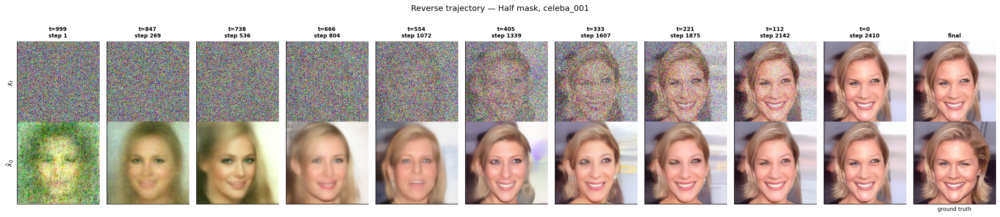

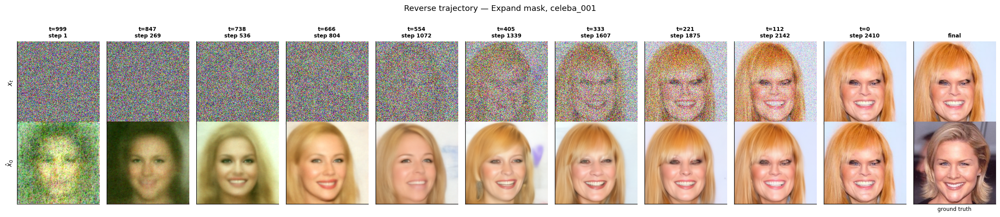

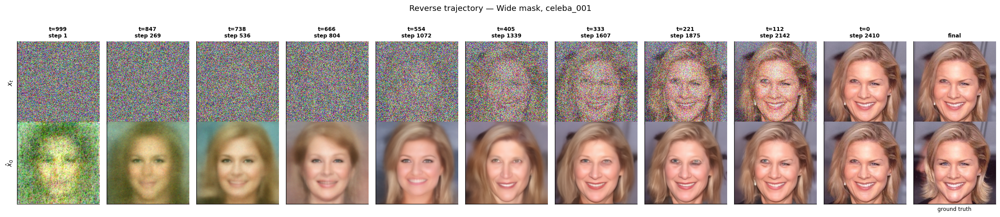

In [18]:
def plot_trajectory(k):
    key = item_key(0, k, base_seed(0), T_STEPS, JUMP_LENGTH, JUMP_N_SAMPLE)
    caps = STORE["captures"].get(key)
    if not caps: return
    fig, axes = plt.subplots(2, len(caps) + 1, figsize=(1.9 * (len(caps) + 1), 4.3))
    for c, cp in enumerate(caps):
        axes[0, c].imshow(to_np_img(cp["x_t"])); axes[1, c].imshow(to_np_img(cp["x0_hat"]))
        axes[0, c].set_title(f"t={cp['t']}\nstep {cp['n_rev']}", fontsize=8)
    axes[0, -1].imshow(to_np_img(main_out[key])); axes[0, -1].set_title("final", fontsize=8)
    axes[1, -1].imshow(to_np_img(X0[0])); axes[1, -1].set_xlabel("ground truth", fontsize=8)
    axes[0, 0].set_ylabel("$x_t$"); axes[1, 0].set_ylabel(r"$\hat{x}_0$")
    for a in axes.ravel(): a.set_xticks([]); a.set_yticks([]); a.grid(False)
    fig.suptitle(f"Reverse trajectory — {MASK_LABEL[k]} mask, {IMG_IDS[0]}", y=1.02)
    plt.tight_layout(); show_and_log(fig, f"process/trajectory_{k}")

for k in ["half", "expand", "wide"]:
    if k in MASK_TYPES: plot_trajectory(k)

### 10.2 · Diversity: several samples for the same input
RePaint is a sampler, not a regressor. Different seeds give different plausible completions for large holes.

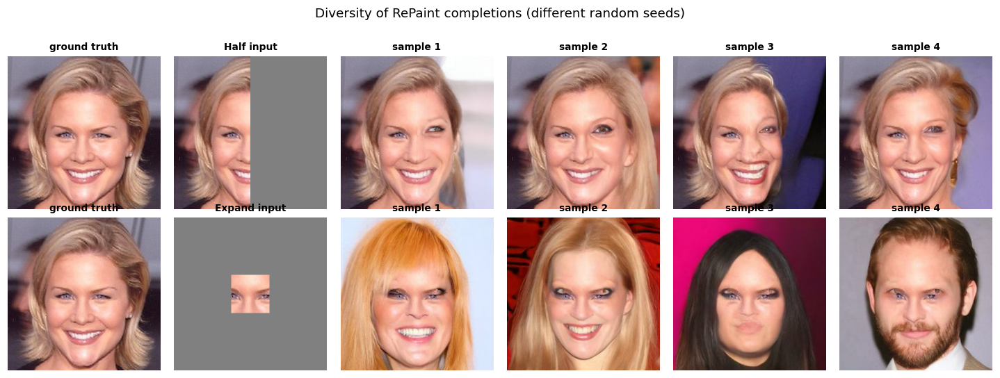

In [19]:
div_masks = [k for k in ["half", "expand"] if k in MASK_TYPES]
if div_masks and N_DIVERSITY > 0:
    fig, axes = plt.subplots(len(div_masks), N_DIVERSITY + 3, figsize=(2.2 * (N_DIVERSITY + 3), 2.4 * len(div_masks)))
    axes = np.atleast_2d(axes)
    for r_, k in enumerate(div_masks):
        axes[r_, 0].imshow(to_np_img(X0[0])); axes[r_, 1].imshow(masked_view(X0[0], MASKS[(k, 0)]))
        for v in range(N_DIVERSITY + 1):
            out = main_out[item_key(0, k, base_seed(0, v), T_STEPS, JUMP_LENGTH, JUMP_N_SAMPLE)]
            axes[r_, 2 + v].imshow(to_np_img(out))
            axes[r_, 2 + v].set_title(f"sample {v + 1}", fontsize=9)
        axes[r_, 0].set_title("ground truth", fontsize=9); axes[r_, 1].set_title(f"{MASK_LABEL[k]} input", fontsize=9)
    for a in axes.ravel(): a.axis("off")
    fig.suptitle("Diversity of RePaint completions (different random seeds)", y=1.02)
    plt.tight_layout(); show_and_log(fig, "results/diversity")

## 11 · Ablations from the paper
### 11.1 · Table 3: jump length j × resamplings r (Wide masks)
The paper ran this on 32 CelebA validation images. Here it runs on the 5 selected images with the same Wide masks as above. Expect noisy numbers with n = 5. The trend is what to compare.

Upper-bound estimate before cache reuse: 109.0 min
[ablation_j_r] 40 new samples in 8 batch(es) on 2 device(s); ~97.1 min estimated


ablation_j_r:   0%|          | 0/19658 [00:00<?, ?step/s]

[ablation_j_r] done in 103.7 min
LPIPS ↓  rows: r, columns: j


ours (CelebA, n=5)                 paper (CelebA val, n=32)              
j                  1       5       10                       1      5      10
5              0.1125  0.1002  0.1062                    0.075  0.072  0.073
10             0.1058  0.0923  0.0982                    0.088  0.073  0.068
15             0.1010  0.1046  0.0884                    0.065  0.063  0.065

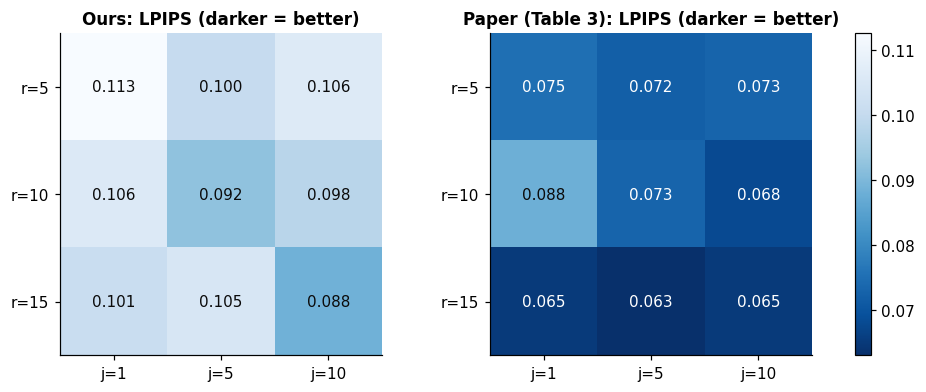

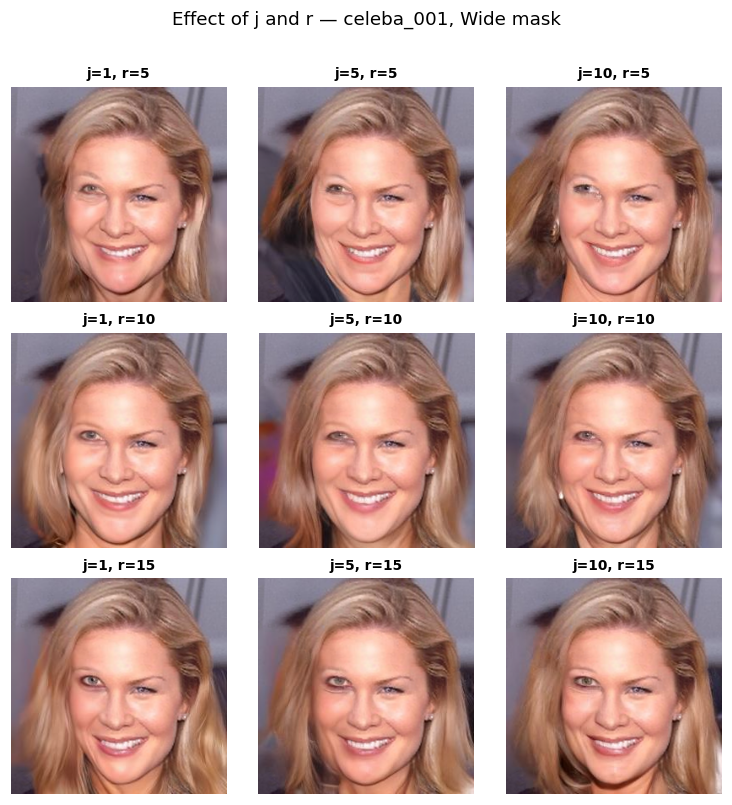

In [20]:
PAPER_T3 = {(5, 1): 0.075, (5, 5): 0.072, (5, 10): 0.073,
            (10, 1): 0.088, (10, 5): 0.073, (10, 10): 0.068,
            (15, 1): 0.065, (15, 5): 0.063, (15, 10): 0.065}       # (r, j) -> LPIPS
if RUN_ABLATION_JR and "wide" in MASK_TYPES:
    items = [item_key(i, "wide", base_seed(i), T_STEPS, j, r) for r in ABLATION_R for j in ABLATION_J for i in range(N_IMAGES)]
    est = sum(n_unet_calls(get_schedule_jump(T_STEPS, 1, j, r)) for r in ABLATION_R for j in ABLATION_J) * N_IMAGES * SEC_PER_IMAGE_STEP / len(DEVICES)
    print(f"Upper-bound estimate before cache reuse: {est/60:.1f} min")
    abl_out = run_items(items, "ablation_j_r")
    df_t3 = evaluate(abl_out, "ablation_j_r")
    t3 = df_t3.groupby(["r", "j"]).LPIPS.mean().unstack("j")
    t3_paper = pd.DataFrame({j: [PAPER_T3.get((r, j), np.nan) for r in ABLATION_R] for j in ABLATION_J}, index=ABLATION_R)
    print("LPIPS ↓  rows: r, columns: j"); display(pd.concat({"ours (CelebA, n=%d)" % N_IMAGES: t3, "paper (CelebA val, n=32)": t3_paper}, axis=1).round(4))

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    both = np.concatenate([t3.values.ravel(), t3_paper.values.ravel()]).astype(float)
    vmin, vmax = np.nanmin(both), np.nanmax(both)
    for a, (name, tab) in zip(axes, [("Ours", t3), ("Paper (Table 3)", t3_paper)]):
        im = a.imshow(tab.values, cmap="Blues_r", vmin=vmin, vmax=vmax)
        a.set_xticks(range(len(tab.columns)), [f"j={j}" for j in tab.columns]); a.set_yticks(range(len(tab.index)), [f"r={r}" for r in tab.index])
        for (ri, ci), v in np.ndenumerate(tab.values):
            if not np.isnan(v): a.text(ci, ri, f"{v:.3f}", ha="center", va="center", fontsize=10,
                                       color="white" if v < (vmin + vmax) / 2 else "#0b0b0b")
        a.set_title(f"{name}: LPIPS (darker = better)"); a.grid(False)
    fig.colorbar(im, ax=axes, fraction=0.025)
    show_and_log(fig, "ablation/table3_j_r_heatmap")

    # qualitative: one image across the grid
    fig, axes = plt.subplots(len(ABLATION_R), len(ABLATION_J), figsize=(2.3 * len(ABLATION_J), 2.4 * len(ABLATION_R)))
    axes = np.atleast_2d(axes)
    for ri, r in enumerate(ABLATION_R):
        for ci, j in enumerate(ABLATION_J):
            axes[ri, ci].imshow(to_np_img(abl_out[item_key(0, "wide", base_seed(0), T_STEPS, j, r)]))
            axes[ri, ci].set_title(f"j={j}, r={r}", fontsize=9); axes[ri, ci].axis("off")
    fig.suptitle(f"Effect of j and r — {IMG_IDS[0]}, Wide mask", y=1.01)
    plt.tight_layout(); show_and_log(fig, "ablation/table3_visual")
    wandb.log({"ablation/table3": wandb.Table(dataframe=t3.reset_index().rename(columns=lambda c: f"j={c}" if isinstance(c, (int, np.integer)) else c))})
    df_t3.to_csv(OUT_DIR / "ablation_table3.csv", index=False)

### 11.2 · Table 2: slowing down vs. resampling at equal compute
Is RePaint's gain just from spending more UNet evaluations? The paper compares *slowing down*, which means more diffusion steps T with r = 1, against *resampling* at T = 250 with r > 1. The two sides have roughly matched compute: r = 2, 3, 4 at T = 250 costs about as much as T = 500, 750, 1000. Paper (ImageNet, Wide): slowing down 0.168 → 0.161, resampling 0.168 → 0.134.

[ablation_slowdown] 30 new samples in 6 batch(es) on 2 device(s); ~21.9 min estimated


ablation_slowdown:   0%|          | 0/4440 [00:00<?, ?step/s]

[ablation_slowdown] done in 23.4 min


,setting,UNet calls,LPIPS (ours),"LPIPS (paper, ImageNet)"
0,"T=250, r=1",250,0.1182,0.168
1,"T=500, r=1",500,0.1205,0.167
2,"T=750, r=1",750,0.1332,0.179
3,"T=1000, r=1",1000,0.1268,0.161
4,"T=250, r=1",250,0.1182,0.168
5,"T=250, r=2",490,0.1061,0.148
6,"T=250, r=3",730,0.1177,0.142
7,"T=250, r=4",970,0.1118,0.134


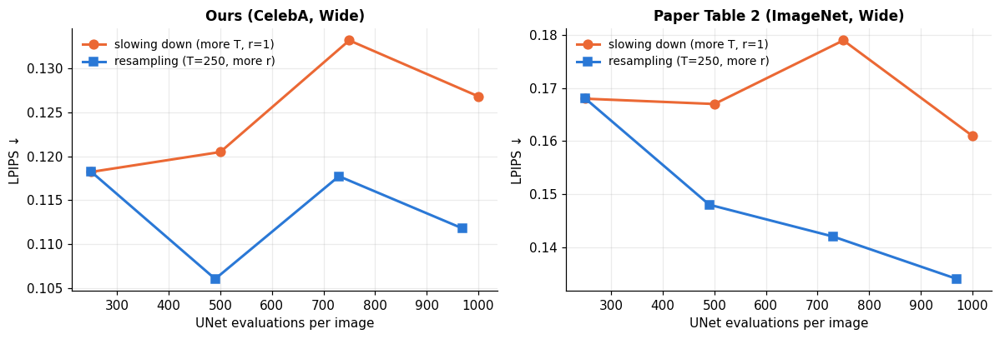

In [21]:
PAPER_T2_SLOW = {250: 0.168, 500: 0.167, 750: 0.179, 1000: 0.161}
PAPER_T2_RES  = {1: 0.168, 2: 0.148, 3: 0.142, 4: 0.134}
if RUN_ABLATION_SLOWDOWN and "wide" in MASK_TYPES:
    slow_items = [item_key(i, "wide", base_seed(i), T, JUMP_LENGTH, 1) for T in SLOWDOWN_T for i in range(N_IMAGES)]
    res_items  = [item_key(i, "wide", base_seed(i), SLOWDOWN_T[0], JUMP_LENGTH, r) for r in RESAMPLE_R for i in range(N_IMAGES)]
    t2_out = run_items(slow_items + res_items, "ablation_slowdown")
    df_t2 = evaluate(t2_out, "ablation_slowdown")
    slow = df_t2[df_t2.r == 1].groupby("T").LPIPS.mean().reindex(SLOWDOWN_T)
    res = df_t2[df_t2["T"] == SLOWDOWN_T[0]].groupby("r").LPIPS.mean().reindex(RESAMPLE_R)
    slow_calls = [n_unet_calls(get_schedule_jump(T, 1, JUMP_LENGTH, 1)) for T in SLOWDOWN_T]
    res_calls = [n_unet_calls(get_schedule_jump(SLOWDOWN_T[0], 1, JUMP_LENGTH, r)) for r in RESAMPLE_R]
    t2 = pd.DataFrame({"setting": [f"T={T}, r=1" for T in SLOWDOWN_T] + [f"T={SLOWDOWN_T[0]}, r={r}" for r in RESAMPLE_R],
                       "UNet calls": slow_calls + res_calls, "LPIPS (ours)": list(slow.values) + list(res.values),
                       "LPIPS (paper, ImageNet)": [PAPER_T2_SLOW.get(T) for T in SLOWDOWN_T] + [PAPER_T2_RES.get(r) for r in RESAMPLE_R]})
    display(t2.round(4))

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
    for a, (title, ys_s, ys_r) in zip(axes, [("Ours (CelebA, Wide)", slow.values, res.values),
                                            ("Paper Table 2 (ImageNet, Wide)", [PAPER_T2_SLOW.get(T, np.nan) for T in SLOWDOWN_T],
                                             [PAPER_T2_RES.get(r, np.nan) for r in RESAMPLE_R])]):
        a.plot(slow_calls, ys_s, "o-", color=C_BASE, lw=2, ms=7, label="slowing down (more T, r=1)")
        a.plot(res_calls, ys_r, "s-", color=C_OURS, lw=2, ms=7, label="resampling (T=250, more r)")
        a.set(xlabel="UNet evaluations per image", ylabel="LPIPS ↓", title=title)
        a.legend(frameon=False, fontsize=9)
    plt.tight_layout(); show_and_log(fig, "ablation/table2_slowdown_vs_resampling")
    wandb.log({"ablation/table2": wandb.Table(dataframe=t2)})
    df_t2.to_csv(OUT_DIR / "ablation_table2.csv", index=False)

## 12 · Summary, artifacts, and W&B finalisation

In [22]:
print("=" * 72)
print(f"RePaint reproduction — {N_IMAGES} images, T={T_STEPS}, j={JUMP_LENGTH}, r={JUMP_N_SAMPLE}, model {MODEL_ID}")
print("=" * 72)
display(table1.round(3))
if len(df_base):
    gain = (df_base.groupby("mask").LPIPS.mean() - df_main.groupby("mask").LPIPS.mean()).reindex(MASK_TYPES)
    print(f"LPIPS improvement from resampling (r=1 minus r={JUMP_N_SAMPLE}; positive = resampling helps):")
    for k in MASK_TYPES: print(f"  {MASK_LABEL[k]:<18} {gain[k]:+.4f}")
    wandb.run.summary["lpips/gain_from_resampling_mean"] = float(gain.mean())
perf = pd.DataFrame(TIMINGS)
if len(perf): display(perf.round(1)); wandb.log({"perf/timings": wandb.Table(dataframe=perf)})

# Bundle everything (figures, CSVs, sample PNGs) for download and as a W&B artifact
archive = shutil.make_archive(str(WORKING_ROOT / "repaint_results"), "zip", root_dir=OUT_DIR)
art = wandb.Artifact("repaint-results", type="results", description="Figures, metrics CSVs and inpainted samples")
art.add_dir(str(FIG_DIR), name="figures"); art.add_dir(str(OUT_DIR / "samples"), name="samples")
for f in OUT_DIR.glob("*.csv"): art.add_file(str(f))
run.log_artifact(art)
wandb.finish()
print(f"Results archive: {archive}")

RePaint reproduction — 5 images, T=250, j=10, r=10, model google/ddpm-celebahq-256


experiment,No resampling (r=1),RePaint (r=10),Paper RePaint (CelebA-HQ),Paper LaMa (CelebA-HQ)
Wide,0.118,0.098,0.059,0.045
Narrow,0.082,0.051,0.028,0.028
Super-Resolve 2×,0.282,0.049,0.029,0.177
Altern. Lines,0.061,0.015,0.009,0.083
Half,0.203,0.191,0.165,0.138
Expand,0.510,0.469,0.435,0.342


LPIPS improvement from resampling (r=1 minus r=10; positive = resampling helps):
  Wide               +0.0200
  Narrow             +0.0301
  Super-Resolve 2×   +0.2331
  Altern. Lines      +0.0461
  Half               +0.0124
  Expand             +0.0411


,experiment,new_samples,seconds
0,main_T250_j10_r10,36,5504.1
1,baseline_r1,30,584.5
2,ablation_j_r,40,6220.1
3,ablation_slowdown,30,1405.4


Results archive: /kaggle/working/repaint_results.zip
